# Исследовательский анализ данных в Python и проверка гипотез. 

- Автор: Савельева Ангелина
- Дата: 22.09.2026

### Цели и задачи проекта

Цели:

Провести исследовательский анализ данных сервиса «Яндекс Афиша» за период с 1 июня по 31 октября 2024 года, чтобы выявить изменения в пользовательских предпочтениях и популярности событий осенью, а также проверить гипотезы о различиях в поведении пользователей мобильных и стационарных устройств. Полученные результаты должны помочь продуктовой команде понять причины сезонных изменений спроса и принять обоснованные решения по развитию сервиса.

Задачи:
1. Предобработка и подготовка данных

 - Загрузить и изучить структуру данных: оценить объём, корректность и соответствие описанию.
 - Проверить данные на пропуски, обработать пропущенные значения.
 - Изучить категориальные и количественные признаки, выявить аномалии и выбросы.
 - Проверить явные и неявные дубликаты, принять решение об их обработке.

2. Исследовательский анализ данных (EDA)

 - Анализ сезонных изменений: изучить динамику заказов по месяцам, сравнить распределение заказов летом и осенью по типам мероприятий, устройствам и возрастным рейтингам.
 - Анализ стоимости билета: рассчитать среднюю выручку с одного билета по типам мероприятий и оценить относительное изменение осенью по сравнению с летом.
 - Анализ пользовательской активности: построить динамику заказов и DAU по дням, рассчитать среднее число заказов на пользователя, изучить недельную цикличность (будни vs выходные).
 - Анализ регионов и партнёров: определить лидеров по числу мероприятий, заказов и выручке, оценить концентрацию рынка и выявить ключевых игроков.

3. Статистическая проверка гипотез

 - Проверить гипотезу о том, что среднее количество заказов на пользователя у мобильных устройств выше, чем у стационарных.
 - Проверить гипотезу о различии во времени между заказами у пользователей мобильных и стационарных устройств.


4. Формулировка выводов и рекомендаций


### Описание данных

Для анализа поступили данные о бронировании билетов на сервисе Яндекс Афиша за период с 1 июня по 31 октября 2024 года. Данные состоят из двух датасетов:

- `final_tickets_orders_df.csv` — информация обо всех заказов билетов, совершённых с двух типов устройств — мобильных и стационарных;
- `final_tickets_events_df.csv` —  информация о событиях, включая город и регион события, а также информация о площадке проведения мероприятия.

### Описание датасета `final_tickets_orders_df`

- `order_id` — уникальный идентификатор заказа;
- `user_id` — уникальный идентификатор пользователя;
- `created_dt_msk` — дата создания заказа (московское время);
- `created_ts_msk` — дата и время создания заказа (московское время);
- `event_id` — идентификатор мероприятия из таблицы `events`;
- `cinema_circuit` — сеть кинотеатров. Если не применимо, то здесь будет значение `'нет'`;
- `age_limit` — возрастное ограничение мероприятия;
- `currency_code` — валюта оплаты, например `rub` для российских рублей;
- `device_type_canonical` — тип устройства, с которого был оформлен заказ, например `mobile` для мобильных устройств, desktop для стационарных;
- `revenue` — выручка от заказа;
- `service_name` — название билетного оператора;
- `tickets_count` — количество купленных билетов;
- `total` — общая сумма заказа;
- `days_since_prev` — количество дней с предыдущей покупки для каждого пользователя. Если покупки не было, то данные содержат пропуск.

### Описание датасета `final_tickets_events_df`

- `event_id` — уникальный идентификатор мероприятия;
- `event_name` — название мероприятия. Аналог поля event_name_code из исходной базы данных;
- `event_type_description` — описание типа мероприятия;
- `event_type_main` — основной тип мероприятия: театральная постановка, концерт и так далее;
- `organizers` — организаторы мероприятия;
- `region_name` — название региона;
- `city_name` — название города;
- `venue_id` — уникальный идентификатор площадки;
- `venue_name` — название площадки;
- `venue_address` — адрес площадки.

Датасет `final_tickets_tenge_df.csv` с информацией о курсе тенге к российскому рублю за 2024 год. Значения в рублях представлено для 100 тенге. 
Датасет содержит такие поля:
- `nominal` — номинал (100 тенге);
- `data` — дата;
- `curs` — курс тенге к рублю;
- `cdx` — обозначение валюты (kzt).


### Содержимое проекта


1. Загрузка данных и знакомство с ними.
2. Предобработка данных.
3. Исследовательский анализ данных.
4. Итоговые выводы и рекомендации.

---

## 1. Загрузка данных и знакомство с ними

Начнём с загрузки библиотек и датасетов `final_tickets_orders_df` и `final_tickets_events_df`. Данные датасетов сохраним в двух переменных: `orders_df` и `events_df`.

In [1]:
# Импортируем библиотеки
import pandas as pd
import numpy as np
from scipy import stats as st
# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt

In [2]:
orders_df = pd.read_csv('/datasets/final_tickets_orders_df.csv')
events_df = pd.read_csv('/datasets/final_tickets_events_df.csv')

In [3]:
orders_df.head()

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,Край билетов,4,10870.99,NaN
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,Мой билет,2,2067.51,NaN
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,За билетом!,4,13984.16,75.0
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,Лови билет!,2,212.28,NaN
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,Билеты без проблем,3,10695.43,83.0


In [4]:
events_df.head()

,event_id,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
0,4436,e4f26fba-da77-4c61-928a-6c3e434d793f,спектакль,театр,№4893,Североярская область,Озёрск,2,1600,"Кладбище искусств ""Проблема"" и партнеры","наб. Загородная, д. 785"
1,5785,5cc08a60-fdea-4186-9bb2-bffc3603fb77,спектакль,театр,№1931,Светополянский округ,Глиноград,54,2196,"Лекции по искусству ""Свет"" Групп","ул. Ягодная, д. 942"
2,8817,8e379a89-3a10-4811-ba06-ec22ebebe989,спектакль,театр,№4896,Североярская область,Озёрск,2,4043,"Кинокомитет ""Золотая"" Инк","ш. Коммуны, д. 92 стр. 6"
3,8849,682e3129-6a32-4952-9d8a-ef7f60d4c247,спектакль,театр,№4960,Каменевский регион,Глиногорск,213,1987,"Выставка ремесел ""Свет"" Лтд","пер. Набережный, д. 35"
4,8850,d6e99176-c77f-4af0-9222-07c571f6c624,спектакль,театр,№4770,Лесодальний край,Родниковец,55,4230,"Фестивальный проект ""Листья"" Групп","пер. Проезжий, д. 9"


In [5]:
# Выводим информацию о датафреймах

orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               290849 non-null  int64  
 1   user_id                290849 non-null  object 
 2   created_dt_msk         290849 non-null  object 
 3   created_ts_msk         290849 non-null  object 
 4   event_id               290849 non-null  int64  
 5   cinema_circuit         290849 non-null  object 
 6   age_limit              290849 non-null  int64  
 7   currency_code          290849 non-null  object 
 8   device_type_canonical  290849 non-null  object 
 9   revenue                290849 non-null  float64
 10  service_name           290849 non-null  object 
 11  tickets_count          290849 non-null  int64  
 12  total                  290849 non-null  float64
 13  days_since_prev        268909 non-null  float64
dtypes: float64(3), int64(4), object(7)
m

In [6]:
events_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22427 entries, 0 to 22426
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   event_id                22427 non-null  int64 
 1   event_name              22427 non-null  object
 2   event_type_description  22427 non-null  object
 3   event_type_main         22427 non-null  object
 4   organizers              22427 non-null  object
 5   region_name             22427 non-null  object
 6   city_name               22427 non-null  object
 7   city_id                 22427 non-null  int64 
 8   venue_id                22427 non-null  int64 
 9   venue_name              22427 non-null  object
 10  venue_address           22427 non-null  object
dtypes: int64(3), object(8)
memory usage: 1.9+ MB


Промежуточный вывод:

df_orders: 290 849 строк, 14 столбцов, ~31 МБ.
df_events: 22 427 строк, 11 столбцов, ~1.9 МБ.
Объём достаточен для анализа: почти 300 тыс. заказов и более 22 тыс. мероприятий. Связь между таблицами — по event_id.<br>
Данные загружены корректно, объём достаточный.<br>
Основные проблемы: даты в строковом формате и пропуски в days_since_prev (7.5%).<br>
Требуется стандартная предобработка: преобразование типов, проверка дубликатов и выбросов, обработка пропусков, объединение с таблицей событий и раздельный анализ валют. После этих шагов данные будут готовы к исследовательскому анализу.

## Предобработка данных и подготовка их к исследованию

Сравнение выгрузок в DBeaver показал соотвествие количества строк, столбцов и агрегаты по ключевым числовым полям с данными из датафреймов 

### Проверка на пропуски

In [7]:
display(orders_df.isnull().sum(),
events_df.isnull().sum())

order_id                     0
user_id                      0
created_dt_msk               0
created_ts_msk               0
event_id                     0
cinema_circuit               0
age_limit                    0
currency_code                0
device_type_canonical        0
revenue                      0
service_name                 0
tickets_count                0
total                        0
days_since_prev          21940
dtype: int64

event_id                  0
event_name                0
event_type_description    0
event_type_main           0
organizers                0
region_name               0
city_name                 0
city_id                   0
venue_id                  0
venue_name                0
venue_address             0
dtype: int64

Мы видим пропуски только в столбце days_since_prev, что нормально - некторые пользователи могли не совершить повторную покупку в нашем диапазоне дат.


In [8]:
# объединим датасеты для удобства предобработки данных
df_all = orders_df.merge(events_df, on = 'event_id', how = 'left')

In [9]:
df_all.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 290849 entries, 0 to 290848
Data columns (total 24 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                290849 non-null  int64  
 1   user_id                 290849 non-null  object 
 2   created_dt_msk          290849 non-null  object 
 3   created_ts_msk          290849 non-null  object 
 4   event_id                290849 non-null  int64  
 5   cinema_circuit          290849 non-null  object 
 6   age_limit               290849 non-null  int64  
 7   currency_code           290849 non-null  object 
 8   device_type_canonical   290849 non-null  object 
 9   revenue                 290849 non-null  float64
 10  service_name            290849 non-null  object 
 11  tickets_count           290849 non-null  int64  
 12  total                   290849 non-null  float64
 13  days_since_prev         268909 non-null  float64
 14  event_name          

In [10]:
# Для категориальных значений проверим, какие категории присутствуют в данных
cat_cols = df_all.select_dtypes(include='object').columns.tolist()

for col in cat_cols:
    display(df_all[col].unique())

array(['0002849b70a3ce2', '0005ca5e93f2cf4', '000898990054619', ...,
       'fffcd3dde79eb2c', 'fffeeb3c120cf0b', 'ffff00725179321'],
      dtype=object)

array(['2024-08-20', '2024-07-23', '2024-10-06', '2024-07-13',
       '2024-10-04', '2024-10-23', '2024-08-15', '2024-09-29',
       '2024-10-15', '2024-06-20', '2024-06-21', '2024-06-25',
       '2024-07-25', '2024-06-17', '2024-07-04', '2024-09-16',
       '2024-07-02', '2024-08-31', '2024-09-25', '2024-10-25',
       '2024-09-07', '2024-07-08', '2024-07-31', '2024-10-02',
       '2024-10-16', '2024-07-10', '2024-07-21', '2024-07-28',
       '2024-08-02', '2024-08-28', '2024-09-21', '2024-10-09',
       '2024-10-14', '2024-10-27', '2024-10-31', '2024-06-19',
       '2024-09-17', '2024-09-03', '2024-06-02', '2024-07-07',
       '2024-08-09', '2024-10-24', '2024-10-22', '2024-07-19',
       '2024-08-08', '2024-07-11', '2024-06-27', '2024-09-02',
       '2024-10-26', '2024-10-18', '2024-09-09', '2024-09-10',
       '2024-09-27', '2024-08-10', '2024-08-11', '2024-08-12',
       '2024-10-19', '2024-10-11', '2024-07-06', '2024-08-13',
       '2024-07-17', '2024-08-27', '2024-09-01', '2024-

array(['2024-08-20 16:08:03', '2024-07-23 18:36:24',
       '2024-10-06 13:56:02', ..., '2024-10-30 13:37:43',
       '2024-09-24 10:07:42', '2024-09-25 15:12:40'], dtype=object)

array(['нет', 'Другое', 'Киномакс', 'КиноСити', 'Москино', 'ЦентрФильм'],
      dtype=object)

array(['rub', 'kzt'], dtype=object)

array(['mobile', 'desktop'], dtype=object)

... (5 outputs left out)

array(['Каменевский регион', 'Североярская область', 'Озернинский край',
       'Лугоградская область', 'Поленовский край', 'Широковская область',
       'Медовская область', 'Златопольский округ', 'Малиновоярский округ',
       'Яблоневская область', 'Ветренский регион', 'Боровлянский край',
       'Крутоводская область', 'Ягодиновская область',
       'Серебряноярский округ', nan, 'Лесодальний край',
       'Верхоречная область', 'Горицветская область',
       'Речиновская область', 'Травиницкий округ', 'Сосновская область',
       'Серебринская область', 'Травяная область', 'Каменноярский край',
       'Солнечноземская область', 'Светополянский округ',
       'Заречная область', 'Ручейковский край', 'Глиногорская область',
       'Тепляковская область', 'Каменноозёрный край',
       'Солнечнореченская область', 'Зоринский регион',
       'Берёзовская область', 'Лесостепной край', 'Малиновая область',
       'Синегорский регион', 'Луговая область', 'Шанырский регион',
       'Каменоп

array(['Глиногорск', 'Озёрск', 'Родниковецк', 'Кристалевск',
       'Дальнозолотск', 'Радужнополье', 'Радужсвет', 'Кумсай',
       'Верховино', 'Светополье', 'Кокжар', 'Каменский', 'Лесоярич',
       'Никольянов', 'Речинцево', 'Лесозолотск', nan, 'Дальнозерск',
       'Серебрянка', 'Островецк', 'Родниковец', 'Дальнесветск',
       'Луговаярово', 'Ягодиновка', 'Дальнополин', 'Солчелуг', 'Озёрчане',
       'Серебровино', 'Лесоярово', 'Глинополье', 'Глиноград',
       'Дальнесветин', 'Северополье', 'Теплоозеро', 'Горнодолинск',
       'Ордакент', 'Озёрово', 'Луговинск', 'Лугоград', 'Златопольск',
       'Крутовинск', 'Сарыжар', 'Сосновечин', 'Тихоярск', 'Яблонецк',
       'Жаркентай', 'Широковка', 'Синеводов', 'Синеводск', 'Тихосветск',
       'Радужанов', 'Глиногорь', 'Каменосветск', 'Родниковск',
       'Травогород', 'Глинянск', 'Радужинск', 'Поляногорье',
       'Дальнолесье', 'Ручейник', 'Ключеград', 'Ключеводск', 'Поленовино',
       'Речичанск', 'Ключевополье', 'Шаныртау', 'Дальнесо

array(['Сценический центр "Деталь" Групп',
       'Музыкальная школа для детей "Аккаунт" Лтд',
       'Училище искусств "Нирвана" Инк', ...,
       'Университет искусств "Прогресс" Групп',
       'Творческая ярмарка "График" Инк', 'Школа музыки "Парадигма" Лтд'],
      dtype=object)

array(['алл. Машиностроителей, д. 19 стр. 6', 'алл. Шмидта, д. 9 стр. 4',
       'алл. Юбилейная, д. 5/6', ..., 'ш. Безымянное, д. 6',
       'алл. Тепличная, д. 4/1', 'пр. Сплавный, д. 236 к. 918'],
      dtype=object)

In [11]:
df_all.select_dtypes('object').isnull().sum()

user_id                     0
created_dt_msk              0
created_ts_msk              0
cinema_circuit              0
currency_code               0
device_type_canonical       0
service_name                0
event_name                238
event_type_description    238
event_type_main           238
organizers                238
region_name               238
city_name                 238
venue_name                238
venue_address             238
dtype: int64

In [12]:
# Заказы без события
no_event = df_all[df_all['event_name'].isna()]
display(f"Заказов без события: {len(no_event)}")
display(f"Уникальных event_id среди них: {no_event['event_id'].nunique()}")
display(no_event['event_id'].head(19).tolist())

'Заказов без события: 238'

'Уникальных event_id среди них: 19'

[533222,
 533222,
 533222,
 530296,
 530296,
 530296,
 530296,
 530296,
 530296,
 530296,
 532300,
 530296,
 477731,
 536716,
 246804,
 246804,
 532300,
 536731,
 555671]

In [13]:
# Все 238 заказов без события
no_event = df_all[df_all['event_name'].isna()]
display(f"Всего строк: {len(no_event)}")
display(no_event.head(20))

'Всего строк: 238'

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
62,6493246,002ec276eee9b0b,2024-10-14,2024-10-14 16:27:53,533222,нет,6,rub,mobile,78.75,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
63,6493275,002ec276eee9b0b,2024-10-14,2024-10-14 16:22:38,533222,нет,6,rub,mobile,78.75,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
64,6493304,002ec276eee9b0b,2024-10-14,2024-10-14 16:29:20,533222,нет,6,rub,mobile,118.12,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
237,8272280,00da083909dc06b,2024-06-07,2024-06-07 17:50:50,530296,нет,18,rub,mobile,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
238,8272512,00da083909dc06b,2024-06-07,2024-06-07 17:49:16,530296,нет,18,rub,mobile,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
239,8272251,00da083909dc06b,2024-06-07,2024-06-07 17:49:32,530296,нет,18,rub,mobile,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
240,8272338,00da083909dc06b,2024-06-07,2024-06-07 18:31:20,530296,нет,18,rub,mobile,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
241,8272367,00da083909dc06b,2024-06-07,2024-06-07 17:48:55,530296,нет,18,rub,mobile,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
242,8272396,00da083909dc06b,2024-06-07,2024-06-07 17:04:55,530296,нет,18,rub,mobile,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
243,8272425,00da083909dc06b,2024-06-07,2024-06-07 17:50:15,530296,нет,18,rub,mobile,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Промежуточный вывод:

В данных обнаружено 238 заказов (0.08% от всех), для которых отсутствует информация о событии. Уникальных event_id — 19, то есть 19 событий не были найдены в таблице events.

Большинство таких заказов имеют нулевую выручку и относятся к мобильным устройствам. 
Запрос к базе данных events в DBeaver показал, что все события относятся к фильмам. Скорее всего данные пропуски возникли из-за фильтрации в SQL-запросах, из которых составлялись датафреймы. В датафрейме с заказами нет фильрации по фильмам, в датафрейме с событиями есть, поэтому часть заказов оказалась без событий. <br> 
Эти строки решено удалить.

In [14]:
df_all = df_all.dropna(subset=['event_name'])

In [15]:
df_all.select_dtypes('object').isnull().sum()

user_id                   0
created_dt_msk            0
created_ts_msk            0
cinema_circuit            0
currency_code             0
device_type_canonical     0
service_name              0
event_name                0
event_type_description    0
event_type_main           0
organizers                0
region_name               0
city_name                 0
venue_name                0
venue_address             0
dtype: int64

### Проверка ключевых столбцов

In [16]:
# разделим данные по валюте
df_rub = df_all[df_all['currency_code'] == 'rub'].copy()
df_kzt = df_all[df_all['currency_code'] == 'kzt'].copy()

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__
Правильно, что используешь copy()

In [17]:
for name, df in [('RUB', df_rub), ('KZT', df_kzt)]:
    display(f"{name}")
    display(df[['revenue', 'tickets_count']].describe(
        percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
    ))

'RUB'

,revenue,tickets_count
count,285542.000000,285542.000000
mean,548.013929,2.754159
std,871.750181,1.171575
min,-90.760000,1.000000
1%,0.000000,1.000000
5%,16.410000,1.000000
25%,114.170000,2.000000
50%,346.630000,3.000000
75%,793.320000,4.000000
95%,1607.100000,5.000000


'KZT'

,revenue,tickets_count
count,5069.000000,5069.000000
mean,4995.206767,2.762872
std,4916.752776,1.115558
min,0.000000,1.000000
1%,90.270000,1.000000
5%,164.390000,1.000000
25%,518.100000,2.000000
50%,3698.830000,3.000000
75%,7397.660000,4.000000
95%,13784.260000,5.000000


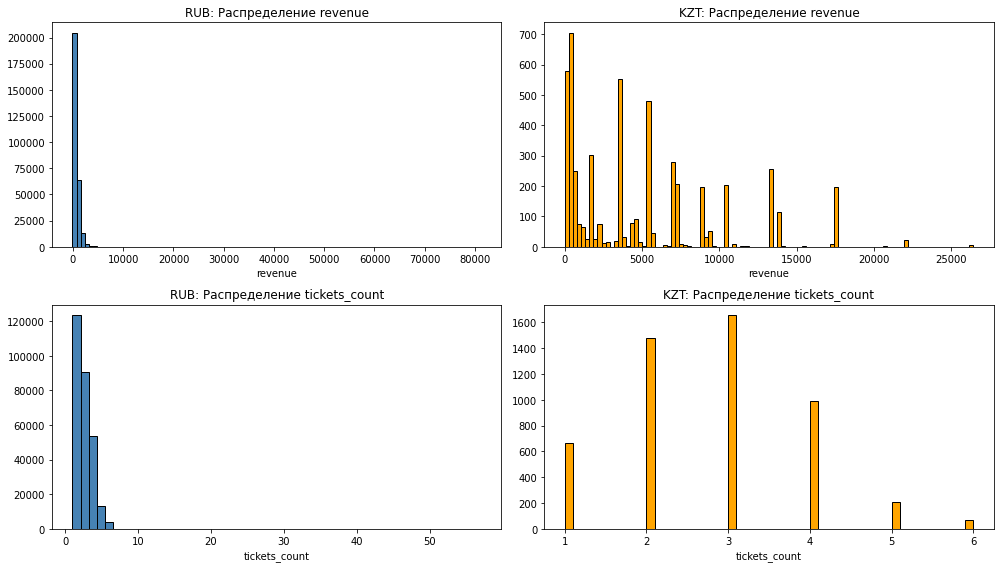

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# revenue (RUB)
axes[0, 0].hist(df_rub['revenue'], bins=100, color='steelblue', edgecolor='black')
axes[0, 0].set_title('RUB: Распределение revenue')
axes[0, 0].set_xlabel('revenue')

# revenue (KZT)
axes[0, 1].hist(df_kzt['revenue'], bins=100, color='orange', edgecolor='black')
axes[0, 1].set_title('KZT: Распределение revenue')
axes[0, 1].set_xlabel('revenue')

# tickets_count (RUB)
axes[1, 0].hist(df_rub['tickets_count'], bins=50, color='steelblue', edgecolor='black')
axes[1, 0].set_title('RUB: Распределение tickets_count')
axes[1, 0].set_xlabel('tickets_count')

# tickets_count (KZT)
axes[1, 1].hist(df_kzt['tickets_count'], bins=50, color='orange', edgecolor='black')
axes[1, 1].set_title('KZT: Распределение tickets_count')
axes[1, 1].set_xlabel('tickets_count')

plt.tight_layout()
plt.show()

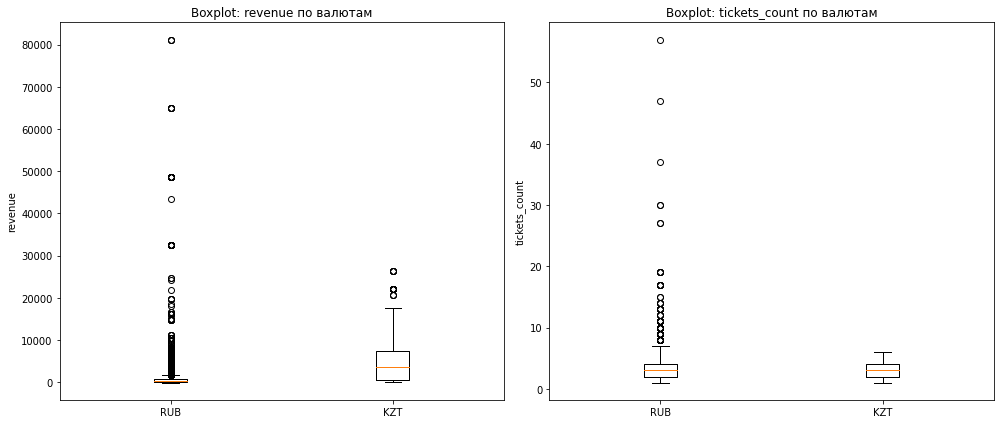

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].boxplot([df_rub['revenue'], df_kzt['revenue']], labels=['RUB', 'KZT'])
axes[0].set_title('Boxplot: revenue по валютам')
axes[0].set_ylabel('revenue')

axes[1].boxplot([df_rub['tickets_count'], df_kzt['tickets_count']], labels=['RUB', 'KZT'])
axes[1].set_title('Boxplot: tickets_count по валютам')
axes[1].set_ylabel('tickets_count')

plt.tight_layout()
plt.show()

Промежуточный вывод:

RUB имеет тяжёлый правый хвост по revenue — обязательна фильтрация по 99-му процентилю.
KZT — более однородные данные.
По tickets_count поведение в двух странах схоже (медиана 3 билета), но RUB содержит единичные экстремальные заказы (до 57 билетов). 

In [20]:
# отсекаем по 99-процентилю
rev_p99_rub = df_rub['revenue'].quantile(0.99)  
df_rub_clean = df_rub[df_rub['revenue'] <= rev_p99_rub].copy()

rev_p99_kzt = df_kzt['revenue'].quantile(0.99) 
df_kzt_clean = df_kzt[df_kzt['revenue'] <= rev_p99_kzt].copy()

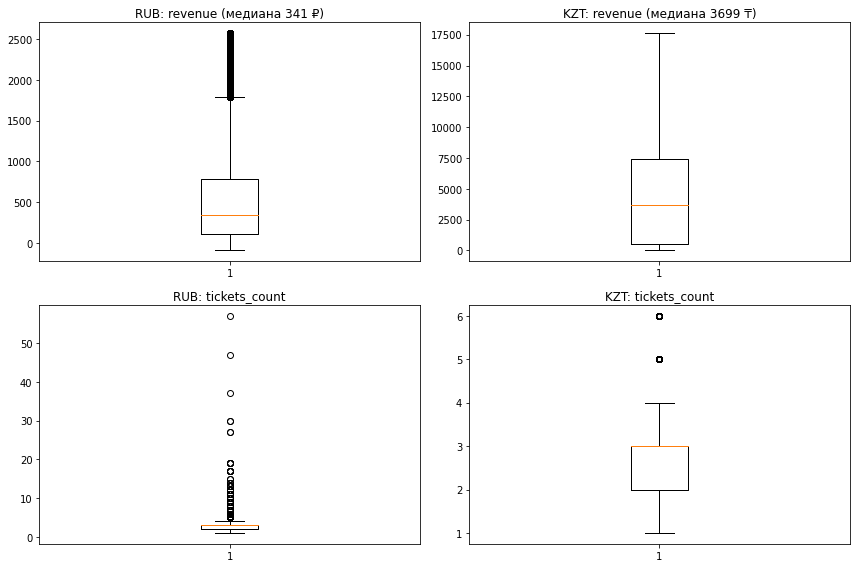

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].boxplot(df_rub_clean['revenue'])
axes[0, 0].set_title(f'RUB: revenue (медиана {df_rub_clean["revenue"].median():.0f} ₽)')

axes[0, 1].boxplot(df_kzt_clean['revenue'])
axes[0, 1].set_title(f'KZT: revenue (медиана {df_kzt_clean["revenue"].median():.0f} ₸)')

axes[1, 0].boxplot(df_rub_clean['tickets_count'])
axes[1, 0].set_title('RUB: tickets_count')

axes[1, 1].boxplot(df_kzt_clean['tickets_count'])
axes[1, 1].set_title('KZT: tickets_count')

plt.tight_layout()
plt.show()

In [22]:
df_clean = pd.concat([df_rub_clean, df_kzt_clean])

### Проверка на дубликаты

In [23]:
df_clean.duplicated().sum()

0

In [24]:
df_clean.duplicated(subset=['order_id']).sum()

0

In [25]:
key_cols = [
    'user_id', 'event_id', 'created_ts_msk',
    'tickets_count', 'total', 'revenue',
    'currency_code', 'device_type_canonical', 'service_name'
]
dup_mask = df_clean.duplicated(subset=key_cols, keep=False)
implicit_dups = df_clean[dup_mask]

display(f"Строк в неявных дубликатах: {len(implicit_dups)}")
display(f"Уникальных комбинаций: {implicit_dups.groupby(key_cols).ngroups}")

'Строк в неявных дубликатах: 75'

'Уникальных комбинаций: 36'

In [26]:
implicit_dups_sorted = implicit_dups.sort_values(key_cols + ['order_id'])
display(implicit_dups_sorted.head(30))

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
11778,1123867,06eb7897f65b433,2024-08-13,2024-08-13 16:31:07,183706,нет,18,rub,mobile,69.82,...,69796237-909b-42a7-bfb5-c1b8574c4c76,спектакль,театр,№1482,Светополянский округ,Глиноград,54.0,4443.0,"Центр культурного наследия ""Объединение"" и пар...","бул. Карбышева, д. 50"
11777,1123983,06eb7897f65b433,2024-08-13,2024-08-13 16:31:07,183706,нет,18,rub,mobile,69.82,...,69796237-909b-42a7-bfb5-c1b8574c4c76,спектакль,театр,№1482,Светополянский округ,Глиноград,54.0,4443.0,"Центр культурного наследия ""Объединение"" и пар...","бул. Карбышева, д. 50"
26894,1930705,0dc525d7bacbb0d,2024-07-31,2024-07-31 13:26:11,393430,нет,18,rub,desktop,1556.05,...,b33d7a0b-a715-47e3-803e-02482884a73e,концерт,концерты,№5048,Каменевский регион,Глиногорск,213.0,2704.0,"Летний фестиваль ""Симфония"" Лтд","бул. Боровой, д. 8/1 стр. 43"
26896,1930763,0dc525d7bacbb0d,2024-07-31,2024-07-31 13:26:11,393430,нет,18,rub,desktop,1556.05,...,b33d7a0b-a715-47e3-803e-02482884a73e,концерт,концерты,№5048,Каменевский регион,Глиногорск,213.0,2704.0,"Летний фестиваль ""Симфония"" Лтд","бул. Боровой, д. 8/1 стр. 43"
53715,1935113,206ea45ec11d478,2024-10-29,2024-10-29 16:46:54,442183,нет,16,rub,mobile,601.69,...,dcf6f06f-8499-41d7-8bc2-a0e3d7afe313,концерт,концерты,№894,Каменевский регион,Глиногорск,213.0,4363.0,"Студия дизайна ""Лестница"" Лимитед","наб. Школьная, д. 9/8 стр. 7/5"
53717,1935171,206ea45ec11d478,2024-10-29,2024-10-29 16:46:54,442183,нет,16,rub,mobile,601.69,...,dcf6f06f-8499-41d7-8bc2-a0e3d7afe313,концерт,концерты,№894,Каменевский регион,Глиногорск,213.0,4363.0,"Студия дизайна ""Лестница"" Лимитед","наб. Школьная, д. 9/8 стр. 7/5"
57220,160893,2564e3703075008,2024-10-30,2024-10-30 10:04:15,589005,нет,6,rub,mobile,11.23,...,bee8d0cc-282b-492e-9ed8-ec0990f43ffd,выставка,другое,№1810,Яблоневская область,Горяново,11036.0,1656.0,"Модная академия ""Пункт"" Лимитед","бул. Гагарина, д. 39"
57217,160922,2564e3703075008,2024-10-30,2024-10-30 10:04:15,589005,нет,6,rub,mobile,11.23,...,bee8d0cc-282b-492e-9ed8-ec0990f43ffd,выставка,другое,№1810,Яблоневская область,Горяново,11036.0,1656.0,"Модная академия ""Пункт"" Лимитед","бул. Гагарина, д. 39"
68214,3326185,2ecf0a4e24cae13,2024-10-17,2024-10-17 15:25:33,481392,нет,18,rub,mobile,40.33,...,994dca15-357e-4193-9717-fd6e073f1354,спектакль,театр,№5071,Тепляковская область,Горнодолинск,43.0,3873.0,"Клуб истории искусств ""Редкость"" Групп","пр. Маяковского, д. 1"
68215,3326272,2ecf0a4e24cae13,2024-10-17,2024-10-17 15:25:33,481392,нет,18,rub,mobile,40.33,...,994dca15-357e-4193-9717-fd6e073f1354,спектакль,театр,№5071,Тепляковская область,Горнодолинск,43.0,3873.0,"Клуб истории искусств ""Редкость"" Групп","пр. Маяковского, д. 1"


In [27]:
user_summary = implicit_dups.groupby('user_id').agg(
    orders_count=('order_id', 'count'),
    order_ids=('order_id', lambda x: sorted(list(x))),
    unique_events=('event_id', 'nunique'),
    total_revenue=('revenue', 'sum'),
    first_order_time=('created_ts_msk', 'min'),
    last_order_time=('created_ts_msk', 'max'),
    device=('device_type_canonical', 'first'),
    service=('service_name', 'first'),
).sort_values('orders_count', ascending=False)

user_summary['time_diff_sec'] = (
    pd.to_datetime(user_summary['last_order_time']) 
    - pd.to_datetime(user_summary['first_order_time'])
).dt.total_seconds()

display(user_summary)

,orders_count,order_ids,unique_events,total_revenue,first_order_time,last_order_time,device,service,time_diff_sec
user_id,,,,,,,,,
fd4d47438ebb946,7,"[8547809, 8547867, 8547983, 8548012, 8548041, ...",1,7916.57,2024-06-19 15:40:50,2024-06-19 15:40:56,desktop,Билеты без проблем,6.0
7eb4fc207ecc10f,7,"[3463732, 3463819, 5372628, 5372831, 5373179, ...",3,975.30,2024-08-23 14:08:19,2024-10-26 09:39:03,mobile,Билеты без проблем,5513444.0
c68f202c21433f7,6,"[2410887, 2411061, 4569328, 4569357, 4569444, ...",2,178.12,2024-10-09 13:58:41,2024-10-16 17:20:16,mobile,Билеты без проблем,616895.0
c2c6d35ff678ca6,5,"[2767964, 2767993, 2768051, 2768167, 2768196]",1,478.60,2024-08-06 13:26:42,2024-08-06 13:26:42,mobile,Билеты без проблем,0.0
cbe06d8837e87fb,4,"[602012, 2321712, 4739065, 6597994]",1,623.96,2024-10-01 11:11:17,2024-10-01 11:20:05,desktop,Билеты в руки,528.0
ae8e3d5af3036a6,2,"[3320153, 3320211]",1,3698.82,2024-07-30 11:20:46,2024-07-30 11:20:46,mobile,Мой билет,0.0
e333b28575ed7f9,2,"[588411, 589252]",1,81.68,2024-07-28 12:50:38,2024-07-28 12:50:38,mobile,Тебе билет!,0.0
de88a121becea97,2,"[7229759, 7229817]",1,2131.68,2024-09-21 17:21:18,2024-09-21 17:21:18,mobile,Мой билет,0.0
da789c3c9d02285,2,"[7749497, 7749584]",1,78.50,2024-09-09 09:16:02,2024-09-09 09:16:02,mobile,Билеты в руки,0.0


In [28]:
group_check = implicit_dups.groupby(key_cols).agg(
    orders_count=('order_id', 'count'),
    time_diff_sec=('created_ts_msk', lambda x: (pd.to_datetime(x.max()) - pd.to_datetime(x.min())).total_seconds())
).reset_index()
display(group_check[group_check['orders_count'] > 1])

,user_id,event_id,created_ts_msk,tickets_count,total,revenue,currency_code,device_type_canonical,service_name,orders_count,time_diff_sec
0,06eb7897f65b433,183706,2024-08-13 16:31:07,1,997.48,69.82,rub,mobile,Билеты в руки,2,0.0
1,0dc525d7bacbb0d,393430,2024-07-31 13:26:11,3,19450.63,1556.05,rub,desktop,Лови билет!,2,0.0
2,206ea45ec11d478,442183,2024-10-29 16:46:54,2,6016.94,601.69,rub,mobile,Билеты в руки,2,0.0
3,2564e3703075008,589005,2024-10-30 10:04:15,2,280.81,11.23,rub,mobile,Лови билет!,2,0.0
4,2ecf0a4e24cae13,481392,2024-10-17 15:25:33,2,1008.14,40.33,rub,mobile,Билеты без проблем,2,0.0
5,35c4c43710a1e8c,568022,2024-09-28 13:43:54,6,18919.32,1891.93,rub,mobile,Мир касс,2,0.0
6,3ee7dc2e115847f,277504,2024-06-25 07:32:08,3,739.85,59.19,rub,mobile,Билеты в руки,2,0.0
7,7b525118ae656af,588203,2024-10-28 08:33:04,4,674.12,26.96,rub,mobile,Лучшие билеты,2,0.0
8,7eb4fc207ecc10f,298035,2024-08-23 14:08:19,1,3170.95,126.84,rub,mobile,Билеты без проблем,3,0.0
9,7eb4fc207ecc10f,418836,2024-10-26 09:39:03,3,4914.21,294.85,rub,mobile,Лови билет!,2,0.0


In [29]:
df_clean = df_clean.drop_duplicates(subset=key_cols, keep='first')

In [30]:
key_cols = [
    'user_id', 'event_id', 'created_ts_msk',
    'tickets_count', 'total', 'revenue',
    'currency_code', 'device_type_canonical', 'service_name'
]
dup_mask = df_clean.duplicated(subset=key_cols, keep=False)
implicit_dups = df_clean[dup_mask]

display(f"Строк в неявных дубликатах: {len(implicit_dups)}")
display(f"Уникальных комбинаций: {implicit_dups.groupby(key_cols).ngroups}")

'Строк в неявных дубликатах: 0'

'Уникальных комбинаций: 0'

In [31]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 287743 entries, 0 to 290727
Data columns (total 24 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                287743 non-null  int64  
 1   user_id                 287743 non-null  object 
 2   created_dt_msk          287743 non-null  object 
 3   created_ts_msk          287743 non-null  object 
 4   event_id                287743 non-null  int64  
 5   cinema_circuit          287743 non-null  object 
 6   age_limit               287743 non-null  int64  
 7   currency_code           287743 non-null  object 
 8   device_type_canonical   287743 non-null  object 
 9   revenue                 287743 non-null  float64
 10  service_name            287743 non-null  object 
 11  tickets_count           287743 non-null  int64  
 12  total                   287743 non-null  float64
 13  days_since_prev         266031 non-null  float64
 14  event_name          

Промежуточный вывод:

Проверка неявных дубликатов по ключу, включающему user_id, event_id, created_ts_msk, tickets_count, total, revenue, currency_code, device_type_canonical и service_name, выявила 77 строк, образующих 37 уникальных групп. 
Группировка по key_cols с расчётом разницы во времени показала, что во всех группах time_diff_sec = 0.0 — заказы оформлены в одну и ту же секунду. Это указывает на технические дубликаты — двойные или тройные нажатия кнопки «Купить». Принято решение удалить дубликаты, оставив первый заказ в каждой группе: удалено 40 строк.

Дополнительно из выборки исключены 238 заказов без информации о событии (0.08%) — они не могли участвовать в анализе по типам мероприятий и регионам. Также применена фильтрация выбросов по 99-му процентилю отдельно для RUB и KZT — удалено ещё 2 828 строк (1% экстремальных значений выручки).

Итоговый очищенный датафрейм df_all_clean содержит 287 743 строки. Всего удалено 3 106 строк (1.07% исходного объёма). Данные готовы к дальнейшему анализу: пропуски в полях событий отсутствуют, технические дубликаты устранены, выбросы отфильтрованы.

### Преобразование типов данных

In [32]:
# приведем created_dt_msk и created_ts_msk к оптимальному типу
df_clean['created_ts_msk'] = pd.to_datetime(df_clean['created_ts_msk'])
df_clean['created_dt_msk'] = pd.to_datetime(df_clean['created_dt_msk']).dt.normalize()

In [33]:
# снизим размерность для количественных данных
df_clean = df_clean.astype({'tickets_count': 'int8', 'age_limit': 'int8'})

In [34]:
df_clean['days_since_prev'] = df_clean['days_since_prev'].astype('float32')

### Создание новых столбцов

In [35]:
tenge = pd.read_csv('/datasets/final_tickets_tenge_df.csv')
display(tenge.head())
# Приводим дату к datetime
tenge['data'] = pd.to_datetime(tenge['data'])

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


In [36]:
tenge_clean = tenge[['data', 'curs']].rename(columns={'data': 'created_dt_msk'})
df_clean = df_clean.merge(tenge_clean, on='created_dt_msk', how='left')
display(df_clean[['currency_code', 'created_dt_msk', 'revenue', 'curs']].head(10))

,currency_code,created_dt_msk,revenue,curs
0,rub,2024-08-20,1521.94,18.6972
1,rub,2024-07-23,289.45,18.3419
2,rub,2024-10-06,1258.57,19.6475
3,rub,2024-07-13,8.49,18.5010
4,rub,2024-10-04,1390.41,19.6648
5,rub,2024-10-23,902.74,20.0531
6,rub,2024-08-15,917.83,18.7730
7,rub,2024-09-29,47.78,19.3741
8,rub,2024-10-15,74.84,19.7185
9,rub,2024-06-20,1421.91,18.0419


In [37]:
# создаем новый столбец'revenue_rub'
df_clean['revenue_rub'] = df_clean.apply(
    lambda row: row['revenue'] if row['currency_code'] == 'rub'
                else row['revenue'] * row['curs'] / 100,
    axis=1
)

In [38]:
# создаем новый столбец'one_ticket_revenue_rub'
df_clean['one_ticket_revenue_rub'] = df_clean['revenue_rub'] / df_clean['tickets_count']


In [39]:
# создаем новый столбец'month'
df_clean['month'] = df_clean['created_dt_msk'].dt.to_period('M').dt.to_timestamp()

In [40]:
# создаем новый столбец'season'
season_map = {
    12: 'зима', 1: 'зима', 2: 'зима',
    3: 'весна', 4: 'весна', 5: 'весна',
    6: 'лето', 7: 'лето', 8: 'лето',
    9: 'осень', 10: 'осень', 11: 'осень'
}

df_clean['season'] = df_clean['created_dt_msk'].dt.month.map(season_map)

In [41]:
df_clean.head()

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,city_name,city_id,venue_id,venue_name,venue_address,curs,revenue_rub,one_ticket_revenue_rub,month,season
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,...,Глиногорск,213.0,3972.0,"Сценический центр ""Деталь"" Групп","алл. Машиностроителей, д. 19 стр. 6",18.6972,1521.94,380.4850,2024-08-01,лето
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,...,Глиногорск,213.0,2941.0,"Музыкальная школа для детей ""Аккаунт"" Лтд","алл. Шмидта, д. 9 стр. 4",18.3419,289.45,144.7250,2024-07-01,лето
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,...,Глиногорск,213.0,4507.0,"Училище искусств ""Нирвана"" Инк","алл. Юбилейная, д. 5/6",19.6475,1258.57,314.6425,2024-10-01,осень
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,...,Озёрск,2.0,3574.0,"Театр альтернативного искусства ""Ода"" Лимитед","алл. Есенина, д. 243 к. 3/8",18.5010,8.49,4.2450,2024-07-01,лето
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,...,Родниковецк,240.0,1896.0,"Театр кукол ""Огни"" Инкорпорэйтед","ш. Набережное, д. 595 стр. 8",19.6648,1390.41,463.4700,2024-10-01,осень


Промежуточный вывод:

Создали несколько новых столбцов: 
- revenue_rub — привели выручку с заказа к единой валюте — российскому рублю. Для этого использовали датасет с информацией о курсе казахстанского тенге по отношению к российскому рублю final_tickets_tenge_df.csv за 2024 год. Значения в рублях представлены для 100 тенге.
- one_ticket_revenue_rub — рассчитали выручку с продажи одного билета на мероприятие.
- month — выделили месяц оформления заказа в отдельный столбец.
- season — создали столбец с информацией о сезонности, включая такие категории, как: 'лето', 'осень', 'зима', 'весна'.

## Исследовательский анализ данных

### Анализ распределения заказов по сегментам и их сезонные изменения

***Количество заказов по месяцам***

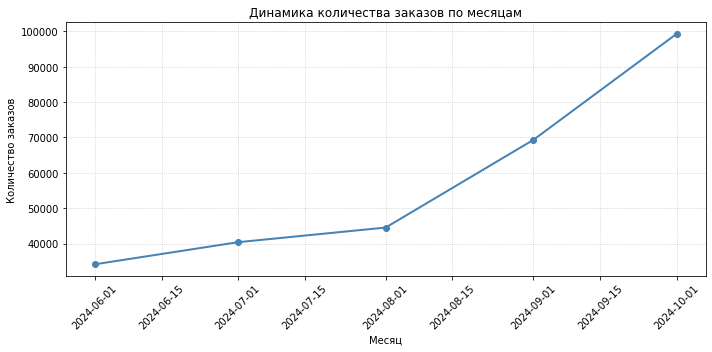

,month,orders
0,2024-06-01,34164
1,2024-07-01,40405
2,2024-08-01,44548
3,2024-09-01,69350
4,2024-10-01,99276


In [42]:
monthly_orders = df_clean.groupby('month').agg(
    orders=('order_id', 'count')
).reset_index()

plt.figure(figsize=(10, 5))
plt.plot(monthly_orders['month'], monthly_orders['orders'],
         marker='o', color='steelblue', linewidth=2)
plt.title('Динамика количества заказов по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество заказов')
plt.grid(True, linestyle=':', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly_orders)

***Сравнение осеннего и летнего периодов по сегментам***

In [43]:
df_season = df_clean[df_clean['season'].isin(['лето', 'осень'])].copy()

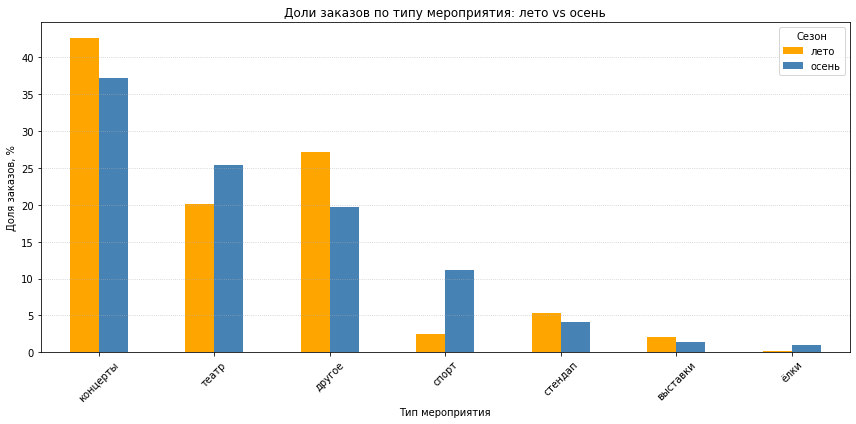

In [44]:
event_share = (df_season
    .groupby(['season', 'event_type_main'])['order_id']
    .count()
    .unstack(0)
    .fillna(0)
)
event_share_pct = event_share.div(event_share.sum(axis=0), axis=1) * 100

event_share_pct = event_share_pct.sort_values('осень', ascending=False)

event_share_pct.plot(kind='bar', figsize=(12, 6), color=['orange', 'steelblue'])
plt.title('Доли заказов по типу мероприятия: лето vs осень')
plt.xlabel('Тип мероприятия')
plt.ylabel('Доля заказов, %')
plt.xticks(rotation=45)
plt.legend(title='Сезон')
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

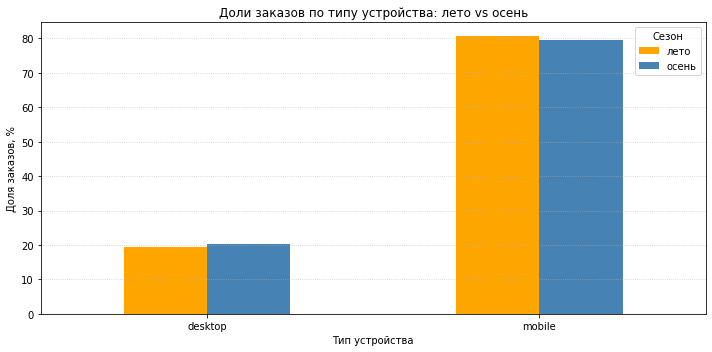

In [45]:
device_share = (df_season
    .groupby(['season', 'device_type_canonical'])['order_id']
    .count()
    .unstack(0)
    .fillna(0)
)

device_share_pct = device_share.div(device_share.sum(axis=0), axis=1) * 100

device_share_pct.plot(kind='bar', figsize=(10, 5), color=['orange', 'steelblue'])
plt.title('Доли заказов по типу устройства: лето vs осень')
plt.xlabel('Тип устройства')
plt.ylabel('Доля заказов, %')
plt.xticks(rotation=0)
plt.legend(title='Сезон')
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

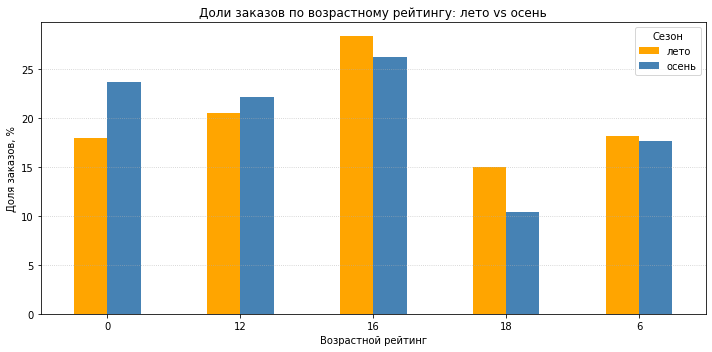

In [46]:
df_season['age_limit_str'] = df_season['age_limit'].astype(str)

age_share = (df_season
    .groupby(['season', 'age_limit_str'])['order_id']
    .count()
    .unstack(0)
    .fillna(0)
)

age_share_pct = age_share.div(age_share.sum(axis=0), axis=1) * 100

age_share_pct.plot(kind='bar', figsize=(10, 5), color=['orange', 'steelblue'])
plt.title('Доли заказов по возрастному рейтингу: лето vs осень')
plt.xlabel('Возрастной рейтинг')
plt.ylabel('Доля заказов, %')
plt.xticks(rotation=0)
plt.legend(title='Сезон')
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

Промежуточные выводы:

Сравнение летнего и осеннего периодов показало, что сезонность заметно влияет на структуру заказов, но по-разному в каждом разрезе.

По типу мероприятия осенью происходит перераспределение спроса: доля концертов снижается (с ~43% до ~37%), тогда как театр и спорт усиливают позиции. Доля театра растёт с ~20% до ~26%, а спорта — с ~3% до ~11%. Категория «Другое» теряет популярность (с ~27% до ~20%). Также в осенней выборке появляются ёлки — традиционный сезонный формат. Таким образом, осенью интерес смещается от массовых концертов к более разнообразным и камерным событиям.

По типу устройства значимых изменений не наблюдается: мобильные устройства стабильно занимают около 80% заказов в оба сезона, доля десктопа остаётся на уровне 20%. Сезонность практически не влияет на выбор устройства для покупки билетов.

По возрастному рейтингу осенью заметно растёт доля мероприятий с рейтингом 0+ (с ~17,5% до ~24%), что может быть связано с семейными походами и детскими событиями. Одновременно снижается доля категории 18+ (с ~15% до ~10,5%). Категория 16+ остаётся самой популярной, но её доля немного уменьшается (с ~28% до ~26%). Таким образом, осенний спрос смещается в сторону более «семейного» и менее «взрослого» контента.

***Средняя выручка с билета по типам мероприятий***

In [47]:
avg_ticket = (df_season
    .groupby(['event_type_main', 'season'])['one_ticket_revenue_rub']
    .mean()
    .unstack(1)
)
avg_ticket['изменение_%'] = (avg_ticket['осень'] / avg_ticket['лето'] - 1) * 100

avg_ticket = avg_ticket.sort_values('осень', ascending=False)

display(avg_ticket.round(2))

season,лето,осень,изменение_%
event_type_main,,,
концерты,304.79,268.36,-11.95
стендап,218.52,231.12,5.77
ёлки,271.44,229.59,-15.42
театр,214.14,175.98,-17.82
выставки,86.42,90.60,4.85
другое,77.44,76.12,-1.71
спорт,50.76,49.97,-1.56


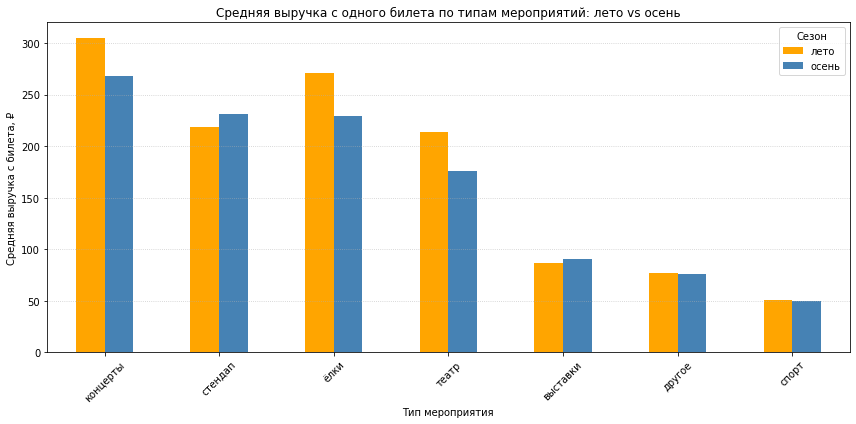

In [48]:
avg_ticket[['лето', 'осень']].plot(kind='bar', figsize=(12, 6), color=['orange', 'steelblue'])
plt.title('Средняя выручка с одного билета по типам мероприятий: лето vs осень')
plt.xlabel('Тип мероприятия')
plt.ylabel('Средняя выручка с билета, ₽')
plt.xticks(rotation=45)
plt.legend(title='Сезон')
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

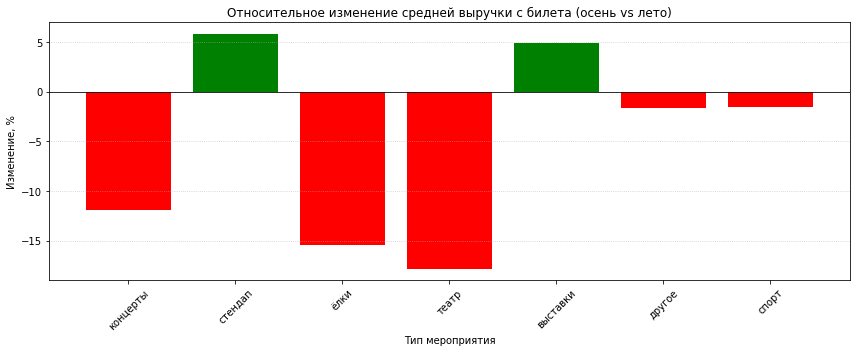

In [49]:
plt.figure(figsize=(12, 5))
colors = ['green' if x > 0 else 'red' for x in avg_ticket['изменение_%']]
plt.bar(avg_ticket.index, avg_ticket['изменение_%'], color=colors)
plt.title('Относительное изменение средней выручки с билета (осень vs лето)')
plt.xlabel('Тип мероприятия')
plt.ylabel('Изменение, %')
plt.axhline(0, color='black', linewidth=0.8)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

Промежуточный вывод:

С наступлением осени структура заказов и ценообразование меняются в сторону большей доступности:

Доля концертов и «других» категорий снижается, зато растёт доля театра и спорта — более «регулярных» и менее «событийных» форматов.<br>
В большинстве категорий средняя стоимость билета падает, особенно в театре и на концертах.<br>
Единственные исключения — стендап (+5,8%) и выставки (+4,9%), где билеты дорожают, но доля заказов снижается.<br>
Общий вектор: осенью билеты становятся дешевле, а спрос смещается от массовых летних концертов к более регулярным и доступным форматам — театру, спорту, детским мероприятиям.<br>
Это подтверждает гипотезу о сезонном изменении пользовательских предпочтений и позволяет прогнозировать, что осенний сезон будет более «семейным» и менее «фестивальным».

### Осенняя активность пользователей

***Динамика изменений***

In [50]:
df_aut = df_clean[df_clean['season'] == 'осень'].copy()

In [51]:
daily = df_aut.groupby('created_dt_msk').agg(
    orders=('order_id', 'count'),
    dau=('user_id', 'nunique'),
    avg_ticket=('one_ticket_revenue_rub', 'mean')
).reset_index()

daily['orders_per_user'] = daily['orders'] / daily['dau']

display(daily.head(10))

,created_dt_msk,orders,dau,avg_ticket,orders_per_user
0,2024-09-01,1327,564,200.168708,2.352837
1,2024-09-02,1380,574,189.464639,2.404181
2,2024-09-03,5113,778,80.350151,6.571979
3,2024-09-04,1773,686,178.048069,2.584548
4,2024-09-05,1944,739,189.510156,2.630582
5,2024-09-06,2126,864,175.309692,2.460648
6,2024-09-07,1958,794,190.241297,2.465995
7,2024-09-08,1713,717,181.973169,2.389121
8,2024-09-09,2093,779,159.725960,2.686778
9,2024-09-10,2024,764,184.053745,2.649215


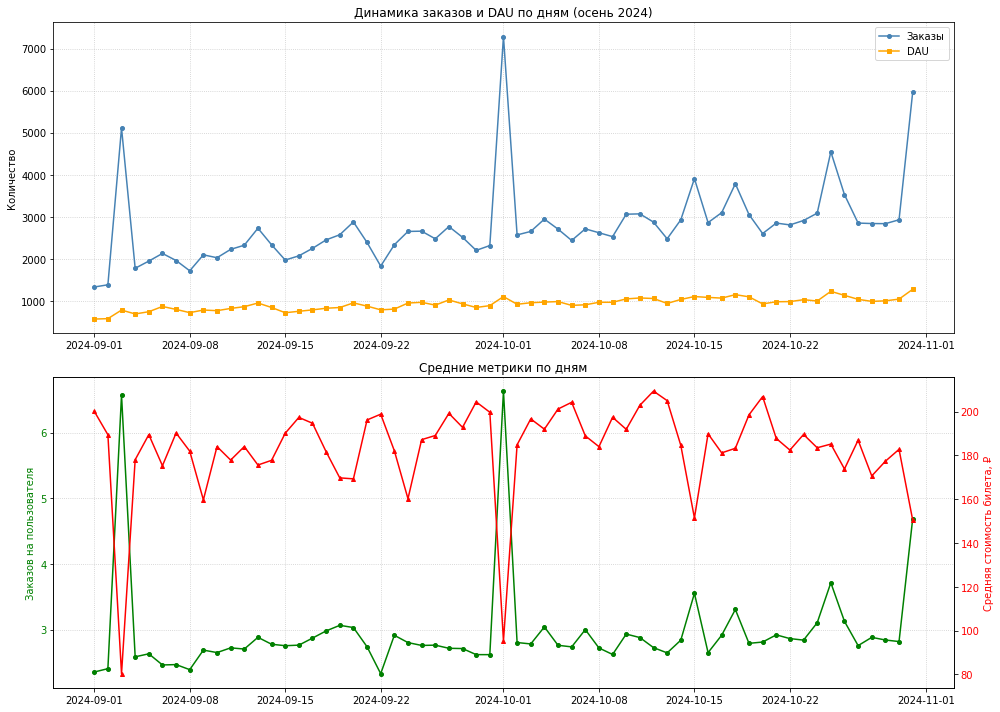

In [52]:
 fig, axes = plt.subplots(2, 1, figsize=(14, 10))

axes[0].plot(daily['created_dt_msk'], daily['orders'],
             marker='o', label='Заказы', color='steelblue', markersize=4)
axes[0].plot(daily['created_dt_msk'], daily['dau'],
             marker='s', label='DAU', color='orange', markersize=4)
axes[0].set_title('Динамика заказов и DAU по дням (осень 2024)')
axes[0].set_ylabel('Количество')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.7)

axes[1].plot(daily['created_dt_msk'], daily['orders_per_user'],
             marker='o', label='Заказов на пользователя', color='green', markersize=4)
axes[1].set_ylabel('Заказов на пользователя', color='green')
axes[1].tick_params(axis='y', labelcolor='green')

ax2 = axes[1].twinx()
ax2.plot(daily['created_dt_msk'], daily['avg_ticket'],
         marker='^', label='Средняя стоимость билета', color='red', markersize=4)
ax2.set_ylabel('Средняя стоимость билета, ₽', color='red')
ax2.tick_params(axis='y', labelcolor='red')

axes[1].set_title('Средние метрики по дням')
axes[1].grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

Осенью 2024 года наблюдается положительная динамика: общее число заказов и количество активных пользователей постепенно увеличиваются. Среднее число заказов на одного пользователя остаётся стабильным, с пиками в отдельные дни. Средняя стоимость билета колеблется, но не демонстрирует чёткой тенденции.

***Недельная цикличность***

In [53]:
daily['day_of_week'] = daily['created_dt_msk'].dt.day_name()
daily['dow_num'] = daily['created_dt_msk'].dt.dayofweek  
day_map = {
    'Monday': 'Пн', 'Tuesday': 'Вт', 'Wednesday': 'Ср',
    'Thursday': 'Чт', 'Friday': 'Пт', 'Saturday': 'Сб', 'Sunday': 'Вс'
}
dow_stats = daily.groupby('dow_num').agg(
    day_name=('day_of_week', 'first'),
    avg_orders=('orders', 'mean'),
    avg_dau=('dau', 'mean'),
    avg_orders_per_user=('orders_per_user', 'mean'),
    avg_ticket=('avg_ticket', 'mean')
).reset_index()

dow_stats['day_name'] = dow_stats['day_name'].map(day_map)
dow_stats = dow_stats.set_index('day_name')

display(dow_stats.round(2))

,dow_num,avg_orders,avg_dau,avg_orders_per_user,avg_ticket
day_name,,,,,
Пн,0,2390.33,853.67,2.78,184.49
Вт,1,3498.78,934.56,3.72,156.67
Ср,2,2543.44,923.56,2.75,185.49
Чт,3,3018.44,962.11,3.06,181.81
Пт,4,3104.38,1022.62,3.00,185.36
Сб,5,2667.62,961.00,2.76,192.50
Вс,6,2154.56,822.78,2.60,197.64


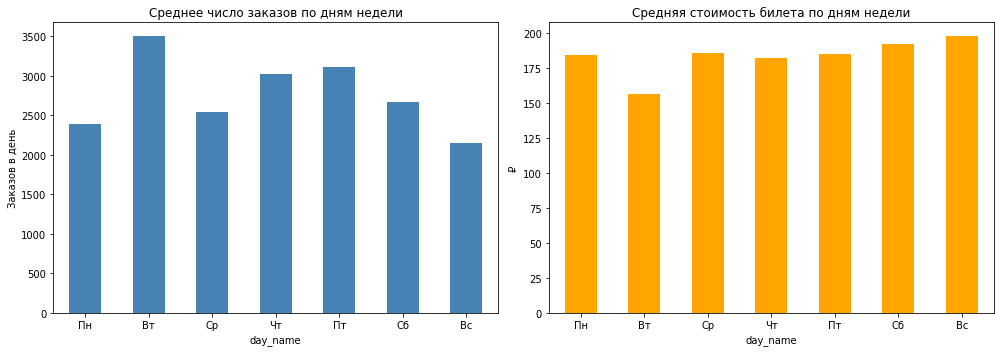

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
dow_stats['avg_orders'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Среднее число заказов по дням недели')
axes[0].set_ylabel('Заказов в день')
axes[0].tick_params(axis='x', rotation=0)

dow_stats['avg_ticket'].plot(kind='bar', ax=axes[1], color='orange')
axes[1].set_title('Средняя стоимость билета по дням недели')
axes[1].set_ylabel('₽')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

Промежуточный вывод:
    
Осенняя активность характеризуется стабильным ростом. Недельная цикличность проявляется в том, что будни дают больше покупок на одного пользователя, а выходные — более высокий средний чек. Пользователи совершают в среднем 2–3 заказа за визит, причём в будни интенсивность покупок немного выше, а в выходные — выше стоимость билета.<br>
Можно выделить явный рабочий ритм, где понедельник–пятница — это дни наибольшей активности, а выходные (суббота и особенно воскресенье) характеризуются спадом активности. А повышенная активность во вторник может быть связана с отложенными заказами после выходных или с внутренними привычками пользователей (например, планирование недели или закупки).

### Популярные события и партнёры

***Распределение по регионам***

In [55]:
region_stats = df_clean.groupby('region_name').agg(
    unique_events=('event_id', 'nunique'),
    total_orders=('order_id', 'count'),
    total_revenue_rub=('revenue_rub', 'sum'),
    unique_users=('user_id', 'nunique')
).reset_index()

region_stats['events_share_%'] = (region_stats['unique_events'] / region_stats['unique_events'].sum() * 100).round(2)
region_stats['orders_share_%'] = (region_stats['total_orders'] / region_stats['total_orders'].sum() * 100).round(2)
region_stats['revenue_share_%'] = (region_stats['total_revenue_rub'] / region_stats['total_revenue_rub'].sum() * 100).round(2)

region_stats = region_stats.sort_values('total_orders', ascending=False)

display(region_stats.head(15))

,region_name,unique_events,total_orders,total_revenue_rub,unique_users,events_share_%,orders_share_%,revenue_share_%
23,Каменевский регион,5935,89662,5.590826e+07,10550,26.54,31.16,37.46
60,Североярская область,3800,43738,2.210465e+07,6692,17.00,15.20,14.81
77,Широковская область,1232,16169,8.628101e+06,3250,5.51,5.62,5.78
42,Медовская область,504,13892,2.927650e+06,1394,2.25,4.83,1.96
45,Озернинский край,349,10405,9.554058e+06,2472,1.56,3.62,6.40
57,Светополянский округ,1075,7501,3.037787e+06,1659,4.81,2.61,2.04
41,Малиновоярский округ,165,6314,5.089834e+06,1831,0.74,2.19,3.41
64,Солнечноземская область,522,6278,1.180949e+06,1068,2.33,2.18,0.79
52,Речиновская область,702,6266,2.630250e+06,1528,3.14,2.18,1.76
78,Яблоневская область,535,6123,3.505459e+06,1422,2.39,2.13,2.35


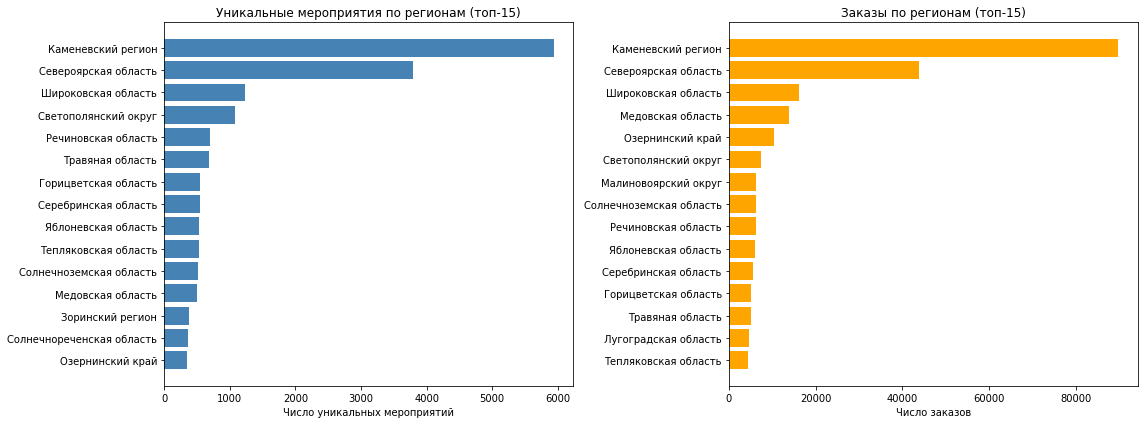

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_events = region_stats.sort_values('unique_events', ascending=False).head(15)
axes[0].barh(top_events['region_name'], top_events['unique_events'], color='steelblue')
axes[0].set_title('Уникальные мероприятия по регионам (топ-15)')
axes[0].set_xlabel('Число уникальных мероприятий')
axes[0].invert_yaxis()

top_orders = region_stats.sort_values('total_orders', ascending=False).head(15)
axes[1].barh(top_orders['region_name'], top_orders['total_orders'], color='orange')
axes[1].set_title('Заказы по регионам (топ-15)')
axes[1].set_xlabel('Число заказов')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

***Распределение по билетным партнёрам***

In [57]:
partner_stats = df_clean.groupby('service_name').agg(
    unique_events=('event_id', 'nunique'),
    total_orders=('order_id', 'count'),
    total_revenue_rub=('revenue_rub', 'sum'),
    unique_users=('user_id', 'nunique'),
    avg_check=('revenue_rub', 'mean')
).reset_index()

partner_stats['events_share_%'] = (partner_stats['unique_events'] / partner_stats['unique_events'].sum() * 100).round(2)
partner_stats['orders_share_%'] = (partner_stats['total_orders'] / partner_stats['total_orders'].sum() * 100).round(2)
partner_stats['revenue_share_%'] = (partner_stats['total_revenue_rub'] / partner_stats['total_revenue_rub'].sum() * 100).round(2)

partner_stats = partner_stats.sort_values('total_revenue_rub', ascending=False)

display(partner_stats.round(2))


,service_name,unique_events,total_orders,total_revenue_rub,unique_users,avg_check,events_share_%,orders_share_%,revenue_share_%
3,Билеты без проблем,4247,62856,24322065.05,8819,386.95,17.42,21.84,16.30
24,Мой билет,1300,34439,22042027.60,6229,640.03,5.33,11.97,14.77
25,Облачко,2335,26402,18588613.86,5341,704.06,9.58,9.18,12.45
21,Лови билет!,4867,40800,16673853.56,6346,408.67,19.96,14.18,11.17
8,Весь в билетах,855,16424,16532346.46,3652,1006.60,3.51,5.71,11.08
5,Билеты в руки,3530,40279,13193688.88,5717,327.56,14.48,14.00,8.84
19,Край билетов,252,6109,6405689.22,1701,1048.57,1.03,2.12,4.29
26,Прачечная,1026,10222,4746810.52,2094,464.37,4.21,3.55,3.18
13,Дом культуры,272,4412,4358655.99,1333,987.91,1.12,1.53,2.92
35,Яблоко,714,5004,3868336.88,1422,773.05,2.93,1.74,2.59


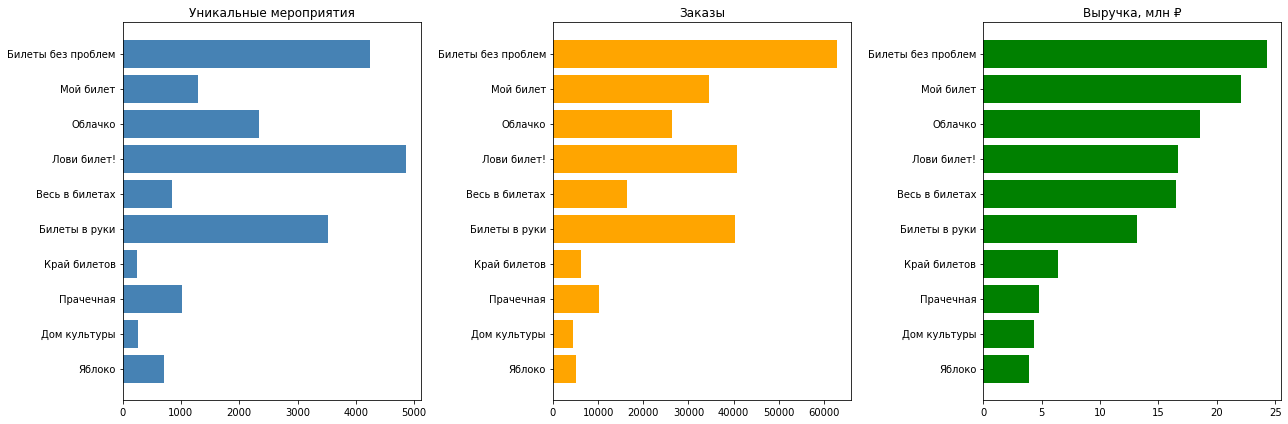

In [58]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

top_partners = partner_stats.head(10)

axes[0].barh(top_partners['service_name'], top_partners['unique_events'], color='steelblue')
axes[0].set_title('Уникальные мероприятия')
axes[0].invert_yaxis()

axes[1].barh(top_partners['service_name'], top_partners['total_orders'], color='orange')
axes[1].set_title('Заказы')
axes[1].invert_yaxis()

axes[2].barh(top_partners['service_name'], top_partners['total_revenue_rub'] / 1e6, color='green')
axes[2].set_title('Выручка, млн ₽')
axes[2].invert_yaxis()

plt.tight_layout()
plt.show()

Промежуточный вывод:

Всего в данных 36 партнёров. <br>
Пять крупнейших аккумулируют ~66% всей выручки: «Билеты без проблем» (16,27%), «Мой билет» (14,78%), «Облачко» (12,47%), «Лови билет!» (11,18%), «Весь в билетах» (11,06%). Остальные 31 партнёр вместе дают лишь треть выручки.<br>
Лидер по числу мероприятий — «Лови билет!» (4 869 событий, 19,95% от всех). Однако по выручке он лишь четвёртый — значит, обрабатывает много недорогих событий.<br>
Лидер по выручке — «Билеты без проблем» (24,26 млн ₽), но по числу событий занимает лишь 3-е место. У него выше средний чек (384,88 ₽) и больше всего заказов (63 020).<br>
Высокий средний чек при малом объёме — у партнёров «Весь в билетах» (1 005 ₽), «Край билетов» (1 049 ₽), «Росбилет» (1 303 ₽), «Дырокол» (1 487 ₽). Это нишевые игроки, работающие с премиум-сегментом.<br>
 Более 20 партнёров имеют долю выручки менее 1% каждый. Некоторые (например, «Зе Бест!», «Билеты в интернете», «Лимоны») — практически не активны. Это создаёт риск зависимости от топ-5 игроков.<br>

Есть один доминирующий лидер, но распределение более равномерное, чем у партнёров.

Всего в данных ~79 регионов. <br>
Один регион — Каменевский — даёт 37,5% выручки, 31,17% заказов и 26,54% всех мероприятий. Это абсолютный лидер по всем метрикам.<br>
Североярская область — второй крупный регион (14,82% выручки, 17% мероприятий). Вместе с Каменевским они формируют более половины (52%) всей выручки.<br>
Широковская область — третий по объёму (5,79% выручки), но значительно отстаёт от первых двух.<br>
Интересный случай — Медовская область: 4,83% заказов, но лишь 1,96% выручки. Это регион с высокой активностью, но низким средним чеком — вероятно, много дешёвых событий.<br>
Озернинский край: наоборот, всего 3,6% заказов, но 6,31% выручки — высокий средний чек, премиум-сегмент.
После топ-15 регионов идёт множество регионов с долей менее 1% каждый. Это типичное распределение для географического рынка: несколько крупных центров и много малых.<br>

Вывод: у партнёров концентрация в топ-10 выше, чем у регионов. Десятка партнёров контролирует почти 86% выручки, тогда как у регионов аналогичная доля требует большего числа игроков. Это говорит о том, что партнёрская сеть более олигополистична, чем географическая.


## Статистический анализ данных

Проверим гипотезы, которые предполагают большую активность пользователей мобильных устройств:


***Среднее количество заказов на одного пользователя мобильного приложения выше по сравнению с пользователями стационарных устройств.***

Формулируем гипотезу:
 - H₀: среднее количество заказов на пользователя у mobile не выше, чем у desktop: μ_mobile ≤ μ_desktop.
 - H₁: среднее количество заказов на пользователя у mobile выше, чем у desktop: μ_mobile > μ_desktop.
 - Уровень значимости: α = 0.05.
 - Тип теста: односторонний (alternative='greater'), так как гипотеза предполагает большую активность mobile.

Будем использовать t-тест. Данный тип актуален, поскольку мы сравниваем средние величины, используем достаточно большие выборки, а также тест устройчив к скошенности при ассимметричных данных.

In [59]:
# проверим пересечения
users_devices = df_aut.groupby('user_id')['device_type_canonical'].nunique()

display(users_devices.value_counts())

1    12562
2     3249
Name: device_type_canonical, dtype: int64

Мы видим 3249 пользователя, которые заказывали с двух типов устройств. Их нужно исключить из выборок.

In [60]:
single_device_users = users_devices[users_devices == 1].index
df_aut_clean = df_aut[df_aut['user_id'].isin(single_device_users)].copy()

In [61]:
user_orders = (
    df_aut_clean.groupby(['device_type_canonical', 'user_id'])
    .agg(orders_count=('order_id', 'count'))
    .reset_index()
)
mob_orders = user_orders[user_orders['device_type_canonical'] == 'mobile']['orders_count']
desk_orders = user_orders[user_orders['device_type_canonical'] == 'desktop']['orders_count']

In [62]:
display("Mobile")
display(f"Среднее: {mob_orders.mean():.2f}")
display(f"Медиана: {mob_orders.median():.1f}")
display(f"Стд. отклонение: {mob_orders.std():.2f}")

display("Desktop")
display(f"Среднее: {desk_orders.mean():.2f}")
display(f"Медиана: {desk_orders.median():.1f}")
display(f"Стд. отклонение: {desk_orders.std():.2f}")
display(f"Mobile: {len(mob_orders)} пользователей")
display(f"Desktop: {len(desk_orders)} пользователей")

'Mobile'

'Среднее: 2.86'

'Медиана: 2.0'

'Стд. отклонение: 4.10'

'Desktop'

'Среднее: 1.97'

'Медиана: 1.0'

'Стд. отклонение: 3.06'

'Mobile: 10943 пользователей'

'Desktop: 1619 пользователей'

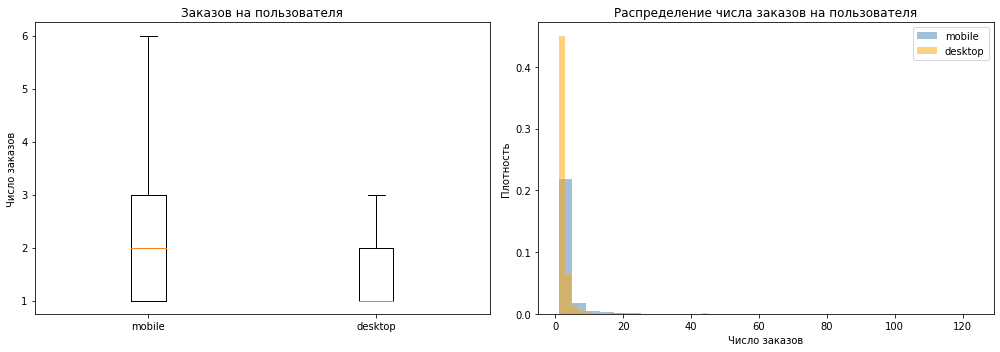

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].boxplot([mob_orders, desk_orders], labels=['mobile', 'desktop'], showfliers=False)
axes[0].set_title('Заказов на пользователя')
axes[0].set_ylabel('Число заказов')

axes[1].hist(mob_orders, bins=30, alpha=0.5, label='mobile', color='steelblue', density=True)
axes[1].hist(desk_orders, bins=30, alpha=0.5, label='desktop', color='orange', density=True)
axes[1].set_title('Распределение числа заказов на пользователя')
axes[1].set_xlabel('Число заказов')
axes[1].set_ylabel('Плотность')
axes[1].legend()

plt.tight_layout()
plt.show()

In [64]:
stat, p_value = st.ttest_ind(
    mob_orders,
    desk_orders,
    equal_var=False,
    alternative='greater'
)

display(f"Среднее mobile: {mob_orders.mean():.2f}")
display(f"Среднее desktop: {desk_orders.mean():.2f}")
display(f"Разница средних: {mob_orders.mean() - desk_orders.mean():.2f}")
display(f"p-value: {p_value:.6f}")

alpha = 0.05
if p_value < alpha:
    display(f"Отвергаем H₀ (p-value < {alpha}). Принимаем H₁: у mobile число заказов значимо выше.")
else:
    display(f"Не отвергаем H₀ (p-value ≥ {alpha}). Статистически значимых различий не обнаружено.")

'Среднее mobile: 2.86'

'Среднее desktop: 1.97'

'Разница средних: 0.89'

'p-value: 0.000000'

'Отвергаем H₀ (p-value < 0.05). Принимаем H₁: у mobile число заказов значимо выше.'

***Среднее время между заказами пользователей мобильных приложений выше по сравнению с пользователями стационарных устройств.***

Формулируем гипотезу:
 - H₀: μ_mobile ≤ μ_desktop — среднее время между заказами у mobile не выше, чем у desktop.
 - H₁: μ_mobile > μ_desktop — среднее время между заказами у mobile выше.
 - Уровень значимости: α = 0.05.
 - Тест: односторонний t-тест Уэлча (equal_var=False, alternative='greater').

In [65]:
user_gap = (
    df_aut_clean.groupby(['device_type_canonical', 'user_id'])
    .agg(avg_days_between_orders=('days_since_prev', 'mean'))
    .reset_index()
    .dropna(subset=['avg_days_between_orders']) # исключаем пользователей с 1 заказом
)

mob_gap = user_gap[user_gap['device_type_canonical'] == 'mobile']['avg_days_between_orders']
desk_gap = user_gap[user_gap['device_type_canonical'] == 'desktop']['avg_days_between_orders']

display(f"Пользователей mobile: {len(mob_gap)}")
display(f"Пользователей desktop: {len(desk_gap)}")

'Пользователей mobile: 7057'

'Пользователей desktop: 894'

In [66]:
display("Mobile")
display(f"Среднее: {mob_gap.mean():.2f}")
display(f"Медиана: {mob_gap.median():.2f}")
display(f"Стд. отклонение: {mob_gap.std():.2f}")

display("Desktop")
display(f"Среднее: {desk_gap.mean():.2f}")
display(f"Медиана: {desk_gap.median():.2f}")
display(f"Стд. отклонение: {desk_gap.std():.2f}")

'Mobile'

'Среднее: 25.25'

'Медиана: 14.00'

'Стд. отклонение: 30.20'

'Desktop'

'Среднее: 31.36'

'Медиана: 16.00'

'Стд. отклонение: 36.56'

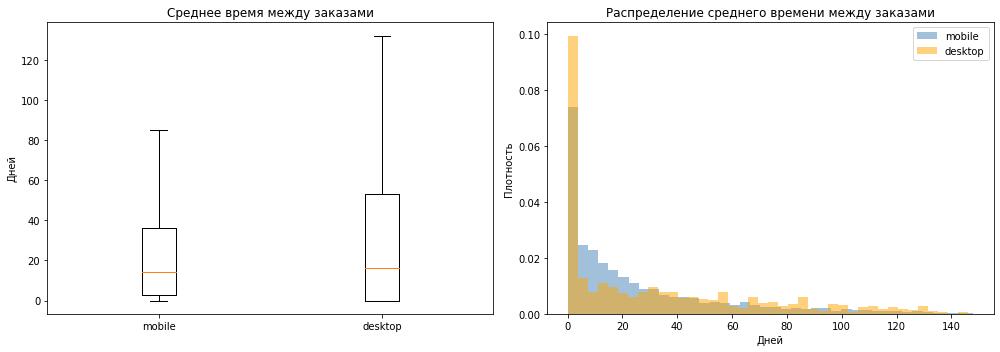

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].boxplot([mob_gap, desk_gap], labels=['mobile', 'desktop'], showfliers=False)
axes[0].set_title('Среднее время между заказами')
axes[0].set_ylabel('Дней')

axes[1].hist(mob_gap, bins=40, alpha=0.5, label='mobile', color='steelblue', density=True)
axes[1].hist(desk_gap, bins=40, alpha=0.5, label='desktop', color='orange', density=True)
axes[1].set_title('Распределение среднего времени между заказами')
axes[1].set_xlabel('Дней')
axes[1].set_ylabel('Плотность')
axes[1].legend()

plt.tight_layout()
plt.show()

In [68]:
stat, p_value = st.ttest_ind(
    mob_gap,
    desk_gap,
    equal_var=False,
    alternative='greater'
)

display("Среднее время между заказами")
display(f"Среднее mobile: {mob_gap.mean():.2f}")
display(f"Среднее desktop: {desk_gap.mean():.2f}")
display(f"Разница средних: {mob_gap.mean() - desk_gap.mean():.2f}")
display(f"p-value: {p_value:.6f}")

alpha = 0.05
if p_value < alpha:
    display(f"Отвергаем H₀ (p-value < {alpha}). Принимаем H₁: у mobile время между заказами значимо выше.")
else:
    display(f"Не отвергаем H₀ (p-value ≥ {alpha}). Статистически значимых различий не обнаружено.")

'Среднее время между заказами'

'Среднее mobile: 25.25'

'Среднее desktop: 31.36'

'Разница средних: -6.10'

'p-value: 0.999999'

'Не отвергаем H₀ (p-value ≥ 0.05). Статистически значимых различий не обнаружено.'

Мы проверяем гипотезы, которые предполагают большую активность пользователей мобильных устройств. Однако в формулировке по заданию второй гипотезы есть логическое несоовтетствие: если у пользователей моббильных устройств среднее время между заказами выше - их активность наоборот ниже. Подтверждение этому результат проверки втророй гиптезы.

Переформулируем гипотезу в соотвествии со смыслом анализа


 - H₀: μ_mobile ≥ μ_desktop — среднее время между заказами у mobile не ниже, чем у desktop.
 - H₁: μ_mobile < μ_desktop — среднее время между заказами у mobile ниже, чем у desktop.

In [69]:
stat, p_value = st.ttest_ind(
    mob_gap,
    desk_gap,
    equal_var=False,
    alternative='less' 
)
display("Среднее время между заказами")
display(f"Среднее mobile: {mob_gap.mean():.2f}")
display(f"Среднее desktop: {desk_gap.mean():.2f}")
display(f"Разница средних: {mob_gap.mean() - desk_gap.mean():.2f}")
display(f"p-value: {p_value:.6f}")

alpha = 0.05
if p_value < alpha:
    display(f"Отвергаем H₀ (p-value < {alpha}). Принимаем H₁: "
          f"у mobile-пользователей среднее время между заказами значимо меньше.")
else:
    display(f"Не отвергаем H₀ (p-value ≥ {alpha}). "
          f"Статистически значимых различий не обнаружено.")

'Среднее время между заказами'

'Среднее mobile: 25.25'

'Среднее desktop: 31.36'

'Разница средних: -6.10'

'p-value: 0.000001'

'Отвергаем H₀ (p-value < 0.05). Принимаем H₁: у mobile-пользователей среднее время между заказами значимо меньше.'

Промежуточный вывод:

Обе гипотезы подтверждаются (в первоначальной формулировке первая подтверждается, вторая не принимается). Пользователи мобильных устройств активнее — они делают больше заказов и возвращаются чаще. Это согласуется с вводной идеей о большей активности mobile-аудитории. Полученные результаты позволяют рекомендовать развитие мобильного канала как приоритетного для удержания и стимулирования повторных покупок.

## Общий вывод и рекомендации

### О данных:

Анализ проведён на основе данных сервиса «Яндекс Афиша» за период 01.06.2024 — 31.10.2024. После объединения таблиц заказов, событий, площадок и регионов получено 287 743 заказа. Из выборки удалены технические дубликаты (40 строк), заказы без информации о событии (238) и 1% экстремальных значений выручки по 99-му процентилю отдельно для RUB и KZT.

### Основные результаты анализа:

- Популярные мероприятия. 
    
    Главный драйвер выручки — концерты (56,5% от общего объёма). На втором месте — театр (23,6%). Вместе они формируют 80% всей выручки.<br> 
    Стендап показывает высокий средний чек при небольшом объёме — перспективная ниша.


- Сезонность.
    Осенью наблюдается устойчивый рост заказов и DAU, пик — в сентябре–октябре. Структура спроса смещается: снижается доля концертов, растёт доля театра  и спорта.<br> 
    Появляется сезонный формат — ёлки. 
    Возрастной рейтинг смещается в сторону 0+ (растёт доля семейных мероприятий) при снижении 18+.<br> 
    Средний чек при этом падает в большинстве категорий, кроме стендапа и выставок.


- Активность пользователей. 
    Ярко выражена недельная цикличность — выходные дают пик заказов и DAU, будни — спад. В будни пользователи оформляют больше заказов на человека (3,07 против 2,68), а в выходные выше средний чек (194,86 ₽ против 172,61 ₽).


- Лидеры среди регионов и партнёров. 
    Среди регионов доминирует Каменевский регион (37,5% выручки, 31,2% заказов).<br> 
    Второй крупный — Североярская область (14,8%). Вместе они дают более половины всей выручки.<br> 
    Среди партнёров высокая концентрация: топ-5 сервисов («Билеты без проблем», «Мой билет», «Облачко», «Лови билет!», «Весь в билетах») аккумулируют ~66% выручки.<br> 
    Партнёрская сеть более олигополистична, чем географическая.

### Результаты проверки гипотез:

Обе гипотезы о большей активности mobile-пользователей подтвердились:

Среднее число заказов на пользователя: mobile — 2,86, desktop — 1,97 (p < 0,05).<br>
Среднее время между заказами: mobile — 25,25 дня, desktop — 31,36 дня (p < 0,05).<br>
Mobile-аудитория активнее по обоим показателям: делает больше заказов и возвращается чаще. Это подтверждает ключевую роль мобильного приложения как основного канала взаимодействия с пользователем.



### Рекомендации

- Развивать мобильное приложение как приоритетный канал. 80% заказов приходятся на mobile, и эти пользователи активнее. Стоит инвестировать в UX, push-уведомления, персонализированные подборки и программы лояльности.
- Диверсифицировать партнёрскую сеть. Зависимость от топ-5 партнёров (66% выручки) — риск. Развитие «среднего» сегмента партнёров снизит уязвимость.
- Сфокусироваться на топ-регионах, но не забывать о «средних». Каменевский регион и Североярская область дают половину выручки — там нужно поддерживать активность. Одновременно стоит изучить регионы с высоким средним чеком (Озернинский край, Малиновоярский округ) для премиум-сегмента.
- Использовать сезонность для планирования маркетинга. Пики заказов — четверг–пятница и выходные, а также сентябрь–октябрь. Промо-кампании лучше запускать в эти периоды.
- Развивать перспективные ниши. Стендап показывает высокий средний чек при небольшом объёме — потенциально растущий сегмент. Ёлки — сезонная возможность с сентября по декабрь.
- Стимулировать возвраты desktop-аудитории. У неё длиннее интервалы между заказами — email-рассылки о крупных событиях и сезонные подборки помогут повысить частоту покупок.